In [2]:
from ucimlrepo import fetch_ucirepo
  
# fetch dataset
statlog_german_credit_data = fetch_ucirepo(id=144) 
  
# data (as pandas dataframes)
X = statlog_german_credit_data.data.features
y = statlog_german_credit_data.data.targets

In [4]:
X.head(5)

,Attribute1,Attribute2,Attribute3,Attribute4,Attribute5,Attribute6,Attribute7,Attribute8,Attribute9,Attribute10,Attribute11,Attribute12,Attribute13,Attribute14,Attribute15,Attribute16,Attribute17,Attribute18,Attribute19,Attribute20
0,A11,6,A34,A43,1169,A65,A75,4,A93,A101,4,A121,67,A143,A152,2,A173,1,A192,A201
1,A12,48,A32,A43,5951,A61,A73,2,A92,A101,2,A121,22,A143,A152,1,A173,1,A191,A201
2,A14,12,A34,A46,2096,A61,A74,2,A93,A101,3,A121,49,A143,A152,1,A172,2,A191,A201
3,A11,42,A32,A42,7882,A61,A74,2,A93,A103,4,A122,45,A143,A153,1,A173,2,A191,A201
4,A11,24,A33,A40,4870,A61,A73,3,A93,A101,4,A124,53,A143,A153,2,A173,2,A191,A201


In [6]:
# das credito o no das credito

y.value_counts()

class
1        700
2        300
Name: count, dtype: int64

In [8]:
# Preprocesamiento de los datos para mejor entedimiento
import pandas as pd

X = pd.DataFrame(X)
X.columns = ['Status',
             'Duration',
             'History',
             'Purpose',
             'Amount',
             'Savings',
             'Employment',
             'Installment',
             'Personal_status',
             'Debtors',
             'Residence_since',
             'Property',
             'Age',
             'Other_installments',
             'Housing',
             'Credits_number',
             'Job',
             'Liable',
             'Telephone',
             'Foreign']
X

,Status,Duration,History,Purpose,Amount,Savings,Employment,Installment,Personal_status,Debtors,Residence_since,Property,Age,Other_installments,Housing,Credits_number,Job,Liable,Telephone,Foreign
0,A11,6,A34,A43,1169,A65,A75,4,A93,A101,4,A121,67,A143,A152,2,A173,1,A192,A201
1,A12,48,A32,A43,5951,A61,A73,2,A92,A101,2,A121,22,A143,A152,1,A173,1,A191,A201
2,A14,12,A34,A46,2096,A61,A74,2,A93,A101,3,A121,49,A143,A152,1,A172,2,A191,A201
3,A11,42,A32,A42,7882,A61,A74,2,A93,A103,4,A122,45,A143,A153,1,A173,2,A191,A201
4,A11,24,A33,A40,4870,A61,A73,3,A93,A101,4,A124,53,A143,A153,2,A173,2,A191,A201
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,A14,12,A32,A42,1736,A61,A74,3,A92,A101,4,A121,31,A143,A152,1,A172,1,A191,A201
996,A11,30,A32,A41,3857,A61,A73,4,A91,A101,4,A122,40,A143,A152,1,A174,1,A192,A201
997,A14,12,A32,A43,804,A61,A75,4,A93,A101,4,A123,38,A143,A152,1,A173,1,A191,A201
998,A11,45,A32,A43,1845,A61,A73,4,A93,A101,4,A124,23,A143,A153,1,A173,1,A192,A201


In [10]:
import numpy as np

X['Status'] = np.where(X['Status'] == 'A11', '<0DM',
                       np.where(X['Status'] == 'A12', '<200DM',
                                np.where(X['Status'] == 'A13', '>200DM', 'No Information')))

In [12]:
X['History'] = np.where(X['History'] == 'A30', 'No Credits taken',
                        np.where(X['History'] == 'A31', 'All credits paid',
                                 np.where(X['History'] == 'A32', 'Existing credits',
                                          np.where(X['History'] == 'A33', 'Delay', 'Critical'))))

In [14]:
X['Purpose'] = np.where(X['Purpose'] == 'A40', 'car',
                        np.where(X['Purpose'] == 'A41', 'car used',
                                 np.where(X['Purpose'] == 'A42', 'furniture',
                                          np.where(X['Purpose'] == 'A43', 'radio',
                                                   np.where(X['Purpose'] == 'A44', 'domestic',
                                                            np.where(X['Purpose'] == 'A45', 'repairs',
                                                                     np.where(X['Purpose'] == 'A46', 'education',
                                                                              np.where(X['Purpose'] == 'A47', 'vacation',
                                                                                       np.where(X['Purpose'] == 'A48', 'retraining',
                                                                                                np.where(X['Purpose'] == 'A49', 'business', 'others'))))))))))

In [16]:
X['Savings'] = np.where(X['Savings'] == 'A61', '<100DM',
                        np.where(X['Savings'] == 'A62', '<500DM',
                                 np.where(X['Savings'] == 'A63', '<1000DM',
                                          np.where(X['Savings'] == 'A64', '>1000DM', 'unknown'))))

In [18]:
X['Employment'] = np.where(X['Employment'] == 'A71', 'unemployed',
                           np.where(X['Employment'] == 'A72', '<1year',
                                    np.where(X['Employment'] == 'A73', '<4years',
                                             np.where(X['Employment'] == 'A74', '<7years','>7years'))))

In [20]:
X['Personal_status'] = np.where(X['Personal_status'] == 'A91', 'male',
                                np.where(X['Personal_status'] == 'A92', 'female',
                                         np.where(X['Personal_status'] == 'A93', 'male-single',
                                                  np.where(X['Personal_status'] == 'A94', 'male-married', 'single'))))

In [22]:
X['Debtors'] = np.where(X['Debtors'] == 'A101', 'none',
                        np.where(X['Debtors'] == 'A102', 'co-applicant', 'guarantor'))

In [24]:
X['Property'] = np.where(X['Property'] == 'A121', 'real state',
                         np.where(X['Property'] == 'A122', 'building',
                                  np.where(X['Property'] == 'A123', 'car', 'unkown')))

In [26]:
X['Other_installments'] = np.where(X['Other_installments'] == 'A141', 'bank',
                                   np.where(X['Other_installments'] == 'A142', 'stores', 'none'))

In [28]:
X['Housing'] = np.where(X['Housing'] == 'A151', 'rent',
                        np.where(X['Housing'] == 'A152', 'own', 'for free'))

In [30]:
X['Job'] = np.where(X['Job'] == 'A171', 'unemployed',
                    np.where(X['Job'] == 'A172', 'unskilled',
                             np.where(X['Job'] == 'A173', 'skilled', 'management')))

In [32]:
X['Telephone'] = np.where(X['Telephone'] == 'A191', 'none', 'yes')

In [34]:
X['Foreign'] = np.where(X['Foreign'] == 'A201', 'yes', 'no')

In [36]:
X.head(5)

,Status,Duration,History,Purpose,Amount,Savings,Employment,Installment,Personal_status,Debtors,Residence_since,Property,Age,Other_installments,Housing,Credits_number,Job,Liable,Telephone,Foreign
0,<0DM,6,Critical,radio,1169,unknown,>7years,4,male-single,none,4,real state,67,none,own,2,skilled,1,yes,yes
1,<200DM,48,Existing credits,radio,5951,<100DM,<4years,2,female,none,2,real state,22,none,own,1,skilled,1,none,yes
2,No Information,12,Critical,education,2096,<100DM,<7years,2,male-single,none,3,real state,49,none,own,1,unskilled,2,none,yes
3,<0DM,42,Existing credits,furniture,7882,<100DM,<7years,2,male-single,guarantor,4,building,45,none,for free,1,skilled,2,none,yes
4,<0DM,24,Delay,car,4870,<100DM,<4years,3,male-single,none,4,unkown,53,none,for free,2,skilled,2,none,yes


In [38]:
X.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 20 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   Status              1000 non-null   object
 1   Duration            1000 non-null   int64 
 2   History             1000 non-null   object
 3   Purpose             1000 non-null   object
 4   Amount              1000 non-null   int64 
 5   Savings             1000 non-null   object
 6   Employment          1000 non-null   object
 7   Installment         1000 non-null   int64 
 8   Personal_status     1000 non-null   object
 9   Debtors             1000 non-null   object
 10  Residence_since     1000 non-null   int64 
 11  Property            1000 non-null   object
 12  Age                 1000 non-null   int64 
 13  Other_installments  1000 non-null   object
 14  Housing             1000 non-null   object
 15  Credits_number      1000 non-null   int64 
 16  Job                 1000 

<Axes: xlabel='y', ylabel='Duration'>

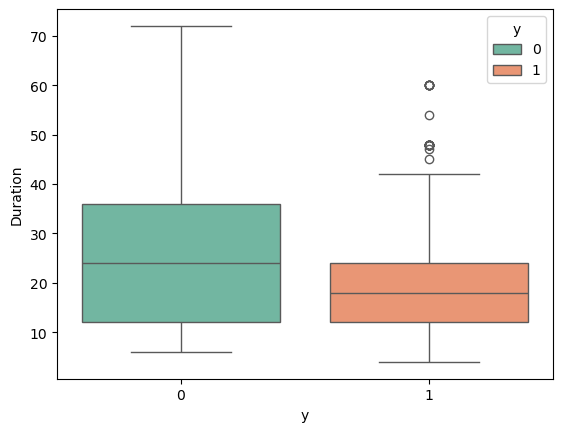

In [50]:
import seaborn as sns

# Agregas la variable objetivo al DataFrame
X['y'] = y


X['y'] = np.where(X['y'] == 1, 1, 0)
# 1 -> Bueno
# 0 -> Malo

sns.boxplot(data = X, x = 'y', y = 'Duration', hue='y', palette='Set2')

In [38]:
X['y'].value_counts(dropna = False)

y
1    700
0    300
Name: count, dtype: int64

<Axes: xlabel='y', ylabel='Amount'>

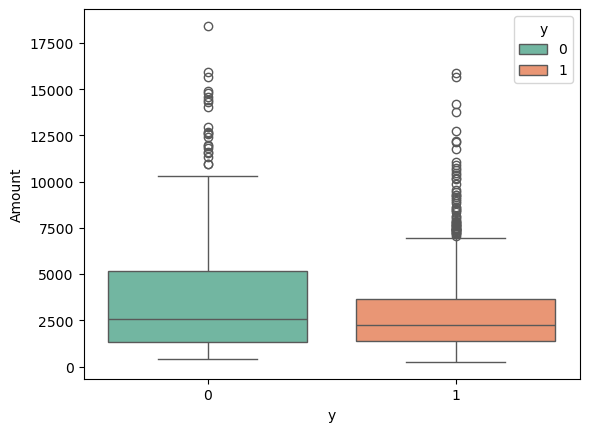

In [52]:
sns.boxplot(data = X, x = 'y', y = 'Amount', hue='y', palette='Set2')

<Axes: xlabel='y', ylabel='Installment'>

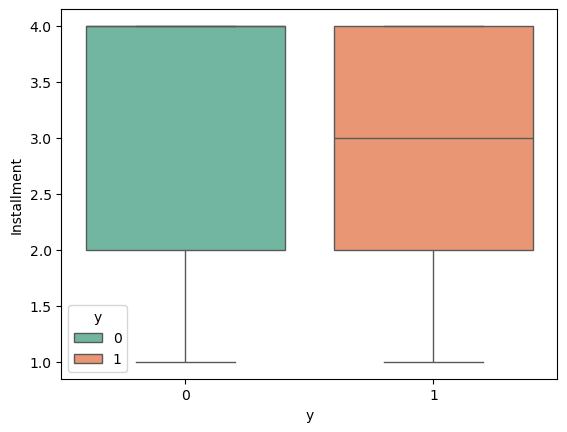

In [54]:
sns.boxplot(data = X, x = 'y', y = 'Installment', hue='y', palette='Set2')

In [56]:
X['Residence_since'].value_counts()

Residence_since
4    413
2    308
3    149
1    130
Name: count, dtype: int64

<Axes: xlabel='y', ylabel='Age'>

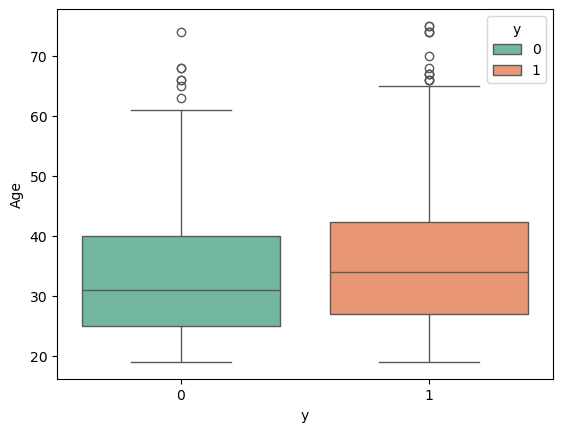

In [58]:
sns.boxplot(data = X, x = 'y', y = 'Age', hue='y', palette='Set2')

In [60]:
X['Credits_number'].value_counts(dropna = False)

Credits_number
1    633
2    333
3     28
4      6
Name: count, dtype: int64

In [62]:
X['Liable'].value_counts(dropna = False)

Liable
1    845
2    155
Name: count, dtype: int64

In [64]:
X.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 21 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   Status              1000 non-null   object
 1   Duration            1000 non-null   int64 
 2   History             1000 non-null   object
 3   Purpose             1000 non-null   object
 4   Amount              1000 non-null   int64 
 5   Savings             1000 non-null   object
 6   Employment          1000 non-null   object
 7   Installment         1000 non-null   int64 
 8   Personal_status     1000 non-null   object
 9   Debtors             1000 non-null   object
 10  Residence_since     1000 non-null   int64 
 11  Property            1000 non-null   object
 12  Age                 1000 non-null   int64 
 13  Other_installments  1000 non-null   object
 14  Housing             1000 non-null   object
 15  Credits_number      1000 non-null   int64 
 16  Job                 1000 

In [66]:
pd.crosstab(X['y'], X['Status'])

Status,<0DM,<200DM,>200DM,No Information
y,,,,
0,135,105,14,46
1,139,164,49,348


In [68]:
pd.crosstab(X['y'], X['History'])

History,All credits paid,Critical,Delay,Existing credits,No Credits taken
y,,,,,
0,28,50,28,169,25
1,21,243,60,361,15


In [70]:
pd.crosstab(X['y'], X['Purpose'])

Purpose,business,car,car used,domestic,education,furniture,others,radio,repairs,retraining
y,,,,,,,,,,
0,34,89,17,4,22,58,5,62,8,1
1,63,145,86,8,28,123,7,218,14,8


In [72]:
pd.crosstab(X['y'], X['Savings'])

Savings,<1000DM,<100DM,<500DM,>1000DM,unknown
y,,,,,
0,11,217,34,6,32
1,52,386,69,42,151


In [74]:
pd.crosstab(X['y'], X['Employment'])

Employment,<1year,<4years,<7years,>7years,unemployed
y,,,,,
0,70,104,39,64,23
1,102,235,135,189,39


In [76]:
X.head()

,Status,Duration,History,Purpose,Amount,Savings,Employment,Installment,Personal_status,Debtors,...,Property,Age,Other_installments,Housing,Credits_number,Job,Liable,Telephone,Foreign,y
0,<0DM,6,Critical,radio,1169,unknown,>7years,4,male-single,none,...,real state,67,none,own,2,skilled,1,yes,yes,1
1,<200DM,48,Existing credits,radio,5951,<100DM,<4years,2,female,none,...,real state,22,none,own,1,skilled,1,none,yes,0
2,No Information,12,Critical,education,2096,<100DM,<7years,2,male-single,none,...,real state,49,none,own,1,unskilled,2,none,yes,1
3,<0DM,42,Existing credits,furniture,7882,<100DM,<7years,2,male-single,guarantor,...,building,45,none,for free,1,skilled,2,none,yes,1
4,<0DM,24,Delay,car,4870,<100DM,<4years,3,male-single,none,...,unkown,53,none,for free,2,skilled,2,none,yes,0


In [78]:
X.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 21 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   Status              1000 non-null   object
 1   Duration            1000 non-null   int64 
 2   History             1000 non-null   object
 3   Purpose             1000 non-null   object
 4   Amount              1000 non-null   int64 
 5   Savings             1000 non-null   object
 6   Employment          1000 non-null   object
 7   Installment         1000 non-null   int64 
 8   Personal_status     1000 non-null   object
 9   Debtors             1000 non-null   object
 10  Residence_since     1000 non-null   int64 
 11  Property            1000 non-null   object
 12  Age                 1000 non-null   int64 
 13  Other_installments  1000 non-null   object
 14  Housing             1000 non-null   object
 15  Credits_number      1000 non-null   int64 
 16  Job                 1000 

In [80]:
a = X.select_dtypes(['int64'])
a

,Duration,Amount,Installment,Residence_since,Age,Credits_number,Liable
0,6,1169,4,4,67,2,1
1,48,5951,2,2,22,1,1
2,12,2096,2,3,49,1,2
3,42,7882,2,4,45,1,2
4,24,4870,3,4,53,2,2
...,...,...,...,...,...,...,...
995,12,1736,3,4,31,1,1
996,30,3857,4,4,40,1,1
997,12,804,4,4,38,1,1
998,45,1845,4,4,23,1,1


##### Llevamos los variables continuas a un nuevo DataFrame y lo estandarizamos

In [82]:
# Procesamiento para el input de la red
from sklearn.preprocessing import StandardScaler

X_numeric = X.select_dtypes(['int64'])
columnas = X_numeric.columns
scaler = StandardScaler()
scaler.fit(X_numeric)

X_numeric = pd.DataFrame(scaler.transform(X_numeric), columns = columnas)
X_numeric.head(5)

,Duration,Amount,Installment,Residence_since,Age,Credits_number,Liable
0,-1.236478,-0.745131,0.918477,1.046987,2.766456,1.027079,-0.428290
1,2.248194,0.949817,-0.870183,-0.765977,-1.191404,-0.704926,-0.428290
2,-0.738668,-0.416562,-0.870183,0.140505,1.183312,-0.704926,2.334869
3,1.750384,1.634247,-0.870183,1.046987,0.831502,-0.704926,2.334869
4,0.256953,0.566664,0.024147,1.046987,1.535122,1.027079,2.334869


##### Llevamos las variables categoricas a un nuevo DataFrame y lo binarizamos

In [84]:
X_categorical = X.select_dtypes(['object'])
X_categorical = pd.get_dummies(X_categorical, dtype = int, drop_first=True)
X_categorical.head(5)

,Status_<200DM,Status_>200DM,Status_No Information,History_Critical,History_Delay,History_Existing credits,History_No Credits taken,Purpose_car,Purpose_car used,Purpose_domestic,...,Property_unkown,Other_installments_none,Other_installments_stores,Housing_own,Housing_rent,Job_skilled,Job_unemployed,Job_unskilled,Telephone_yes,Foreign_yes
0,0,0,0,1,0,0,0,0,0,0,...,0,1,0,1,0,1,0,0,1,1
1,1,0,0,0,0,1,0,0,0,0,...,0,1,0,1,0,1,0,0,0,1
2,0,0,1,1,0,0,0,0,0,0,...,0,1,0,1,0,0,0,1,0,1
3,0,0,0,0,0,1,0,0,0,0,...,0,1,0,0,0,1,0,0,0,1
4,0,0,0,0,1,0,0,1,0,0,...,1,1,0,0,0,1,0,0,0,1


##### Juntamos ambos DataFrames que habiamos realizado

In [86]:
X_data = pd.concat([X_numeric, X_categorical], axis = 1)
X_data.head(5)

,Duration,Amount,Installment,Residence_since,Age,Credits_number,Liable,Status_<200DM,Status_>200DM,Status_No Information,...,Property_unkown,Other_installments_none,Other_installments_stores,Housing_own,Housing_rent,Job_skilled,Job_unemployed,Job_unskilled,Telephone_yes,Foreign_yes
0,-1.236478,-0.745131,0.918477,1.046987,2.766456,1.027079,-0.428290,0,0,0,...,0,1,0,1,0,1,0,0,1,1
1,2.248194,0.949817,-0.870183,-0.765977,-1.191404,-0.704926,-0.428290,1,0,0,...,0,1,0,1,0,1,0,0,0,1
2,-0.738668,-0.416562,-0.870183,0.140505,1.183312,-0.704926,2.334869,0,0,1,...,0,1,0,1,0,0,0,1,0,1
3,1.750384,1.634247,-0.870183,1.046987,0.831502,-0.704926,2.334869,0,0,0,...,0,1,0,0,0,1,0,0,0,1
4,0.256953,0.566664,0.024147,1.046987,1.535122,1.027079,2.334869,0,0,0,...,1,1,0,0,0,1,0,0,0,1


In [88]:
X['y'].value_counts()

y
1    700
0    300
Name: count, dtype: int64

In [90]:
# Preparación de datos para entrenamiento y testeo
from sklearn.model_selection import train_test_split
y = X['y']

X_train, X_test, y_train, y_test = train_test_split(X_data, y, test_size = 0.3, random_state=1234)

In [92]:
from sklearn.ensemble import RandomForestClassifier

model_rf = RandomForestClassifier()

model_rf.fit(X_train, y_train)

RandomForestClassifier()

In [94]:
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix

y_pred_rf = model_rf.predict(X_test)
print(accuracy_score(y_test, y_pred_rf))
print(f1_score(y_test, y_pred_rf))
print(confusion_matrix(y_test, y_pred_rf))

0.7466666666666667
0.8362068965517241
[[ 30  64]
 [ 12 194]]


In [96]:
importancia_variables = model_rf.feature_importances_
importancia_variables = pd.Series(importancia_variables, index = X_train.columns)
importancia_variables.sort_values(ascending = False, inplace = True)

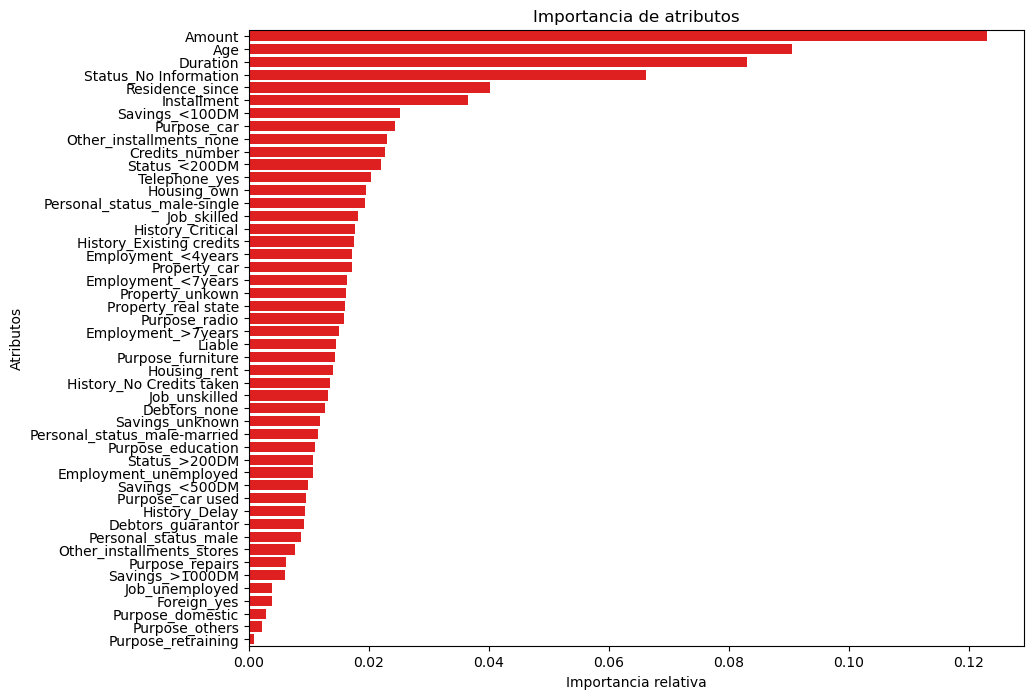

In [98]:
import matplotlib.pyplot as plt

plt.figure(figsize = (10, 8))
sns.barplot(x = importancia_variables, y = importancia_variables.index, color = 'red')
plt.title('Importancia de atributos')
plt.xlabel('Importancia relativa')
plt.ylabel('Atributos')
plt.show()

In [100]:
# Importancia de características al balancear
from imblearn.over_sampling import SMOTE

smote = SMOTE(random_state=42)

X_resampled, y_resampled = smote.fit_resample(X_data, y)

C:\Users\josek\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] El sistema no puede encontrar el archivo especificado
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\josek\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "C:\Users\josek\anaconda3\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\josek\anaconda3\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "C:\Users\josek\anaconda3\Lib\subprocess.py", line 1538, in _execute_child
    hp, ht, pid, tid = _wina

In [102]:
y_resampled.value_counts()

y
1    700
0    700
Name: count, dtype: int64

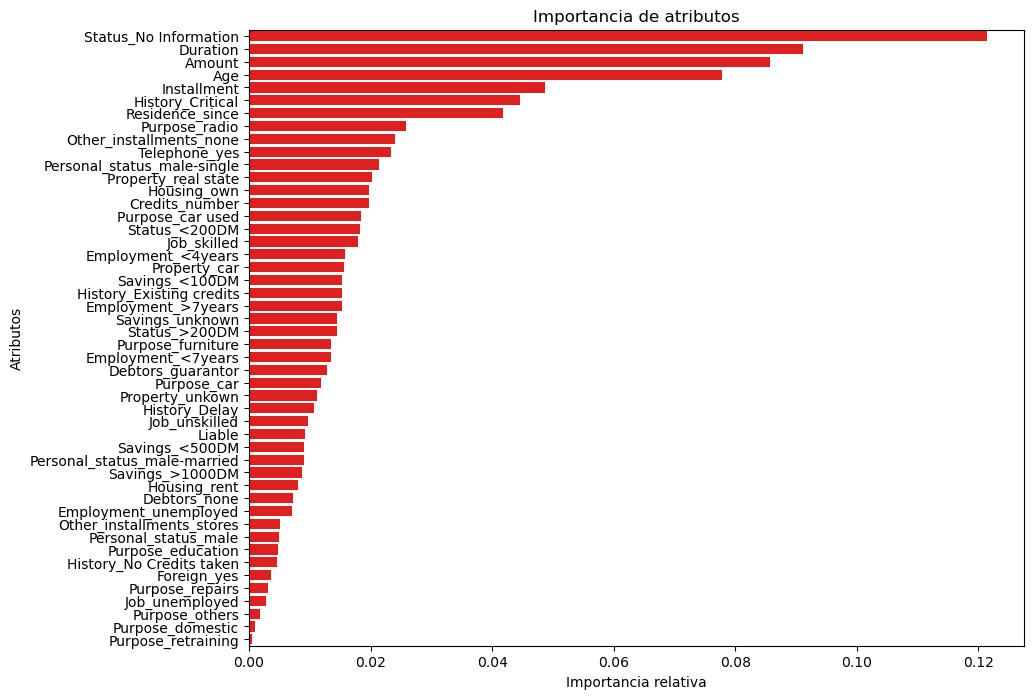

In [104]:
X_train, X_test, y_train, y_test = train_test_split(X_resampled, y_resampled, test_size = 0.3, random_state=1234)

model_rf = RandomForestClassifier()

model_rf.fit(X_train, y_train)

importancia_variables = model_rf.feature_importances_
importancia_variables = pd.Series(importancia_variables, index = X_train.columns)
importancia_variables.sort_values(ascending = False, inplace = True)

plt.figure(figsize = (10, 8))
sns.barplot(x = importancia_variables, y = importancia_variables.index, color = 'red')
plt.title('Importancia de atributos')
plt.xlabel('Importancia relativa')
plt.ylabel('Atributos')
plt.show()

In [106]:
importancia_variables

Status_No Information           0.121440
Duration                        0.091133
Amount                          0.085636
Age                             0.077811
Installment                     0.048724
History_Critical                0.044502
Residence_since                 0.041730
Purpose_radio                   0.025838
Other_installments_none         0.024020
Telephone_yes                   0.023328
Personal_status_male-single     0.021402
Property_real state             0.020211
Housing_own                     0.019738
Credits_number                  0.019701
Purpose_car used                0.018460
Status_<200DM                   0.018307
Job_skilled                     0.017868
Employment_<4years              0.015849
Property_car                    0.015580
Savings_<100DM                  0.015354
History_Existing credits        0.015328
Employment_>7years              0.015276
Savings_unknown                 0.014510
Status_>200DM                   0.014473
Purpose_furnitur

In [108]:
len(importancia_variables)

48

In [110]:
importancia_variables.index[0:50]

Index(['Status_No Information', 'Duration', 'Amount', 'Age', 'Installment',
       'History_Critical', 'Residence_since', 'Purpose_radio',
       'Other_installments_none', 'Telephone_yes',
       'Personal_status_male-single', 'Property_real state', 'Housing_own',
       'Credits_number', 'Purpose_car used', 'Status_<200DM', 'Job_skilled',
       'Employment_<4years', 'Property_car', 'Savings_<100DM',
       'History_Existing credits', 'Employment_>7years', 'Savings_unknown',
       'Status_>200DM', 'Purpose_furniture', 'Employment_<7years',
       'Debtors_guarantor', 'Purpose_car', 'Property_unkown', 'History_Delay',
       'Job_unskilled', 'Liable', 'Savings_<500DM',
       'Personal_status_male-married', 'Savings_>1000DM', 'Housing_rent',
       'Debtors_none', 'Employment_unemployed', 'Other_installments_stores',
       'Personal_status_male', 'Purpose_education', 'History_No Credits taken',
       'Foreign_yes', 'Purpose_repairs', 'Job_unemployed', 'Purpose_others',
       'Purp

In [112]:
variables_utilizar = importancia_variables.index[0:50]
X_data_2 = X_data[variables_utilizar]

In [114]:
X_data_2.head()

,Status_No Information,Duration,Amount,Age,Installment,History_Critical,Residence_since,Purpose_radio,Other_installments_none,Telephone_yes,...,Other_installments_stores,Personal_status_male,Purpose_education,History_No Credits taken,Foreign_yes,Purpose_repairs,Job_unemployed,Purpose_others,Purpose_domestic,Purpose_retraining
0,0,-1.236478,-0.745131,2.766456,0.918477,1,1.046987,1,1,1,...,0,0,0,0,1,0,0,0,0,0
1,0,2.248194,0.949817,-1.191404,-0.870183,0,-0.765977,1,1,0,...,0,0,0,0,1,0,0,0,0,0
2,1,-0.738668,-0.416562,1.183312,-0.870183,1,0.140505,0,1,0,...,0,0,1,0,1,0,0,0,0,0
3,0,1.750384,1.634247,0.831502,-0.870183,0,1.046987,0,1,0,...,0,0,0,0,1,0,0,0,0,0
4,0,0.256953,0.566664,1.535122,0.024147,0,1.046987,0,1,0,...,0,0,0,0,1,0,0,0,0,0


In [116]:
from imblearn.over_sampling import SMOTE

smote = SMOTE(random_state=42)

X_resampled, y_resampled = smote.fit_resample(X_data_2, y)

In [118]:
y_resampled.value_counts()

y
1    700
0    700
Name: count, dtype: int64

In [120]:
# Desarrollo red neuronal artificial

import tensorflow as tf
from keras.models import Sequential
from keras.layers import Dense
from keras.optimizers import SGD
import keras

In [122]:
X_train, X_test, y_train, y_test = train_test_split(X_resampled, y_resampled, test_size=0.3, random_state=1234)

In [124]:
''' 
Esta función recibe tres parámetros:
- capas: El número de capas ocultas que tendrá la red neuronal.
- unit: El número de neuronas (o unidades) en cada capa oculta.
- active: La función de activación que se usará en las capas ocultas.

Capa de entrada
Esta es la capa de entrada de la red, que espera recibir datos con un número de características determinado por X_train.shape[1] 
(es decir, el número de columnas en los datos de entrenamiento X_train).

No hay transformación ni cálculo en esta capa, simplemente define el formato de los datos que serán alimentados a la red.


Capa oculta
for i in range(capas): recorre un bucle que añade tantas capas ocultas como se haya especificado en el parámetro capas
- units = unit: un número de neuronas especificado por el parámetro unit.
- activation = active: la función de activación para cada capa oculta (como 'relu', 'tanh', etc.), que transforma la salida de las neuronas.
- use_bias = True: indica que se utilizarán términos de sesgo (bias) en las neuronas.


Capa de salida
Esta es la capa de salida de la red neuronal.
- units = 1: especifica que la salida tendrá solo una neurona, lo que es común en problemas de clasificación binaria 
(ya que solo se necesita predecir un valor entre dos clases).
- activation = 'sigmoid': la función de activación de la capa de salida es la sigmoide, que devuelve un valor entre 0 y 1, 
lo que es adecuado para modelos de clasificación binaria (ya que representa una probabilidad).
- use_bias = True: se utiliza un término de sesgo también en la capa de salida.

'''

def modelo_ann(capas, unit, active):
    
    ann = Sequential()

    # Capa de entrada
    ann.add(keras.Input(shape = (X_train.shape[1],))) # Ese 1 está ahí para traer el número de columnas de los datos de entrada

    # Capa oculta
    for i in range(capas):
        ann.add(Dense(units = unit, activation = active, use_bias = True))

    # Salida
    ann.add(Dense(units = 1, activation = 'sigmoid', use_bias = True))

    # la función devuelve el modelo neuronal construido con las capas que se agregaron.
    return ann

In [126]:
ann = modelo_ann(capas = 1, unit = 120, active = 'relu') # Recordemos que 1 capa daba 77.7% f1 score

In [128]:
ann.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 120)                 │           5,880 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 1)                   │             121 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 6,001 (23.44 KB)

 Trainable params: 6,001 (23.44 KB)

 Non-trainable params: 0 (0.00 B)

- **La función compile() en Keras se utiliza para configurar el proceso de aprendizaje de la red neuronal**. Aquí se le especifica el optimizador y la función de pérdida que se utilizarán durante el entrenamiento del modelo.
- SGD significa Stochastic Gradient Descent (Descenso de Gradiente Estocástico), que es un algoritmo de optimización usado para ajustar los pesos de la red neuronal durante el entrenamiento.
- learning_rate = 0.001: Este es el tasa de aprendizaje o learning rate, que controla el tamaño de los pasos que el optimizador toma en la dirección opuesta al gradiente.

Funcion de perdida
- La función de pérdida mide qué tan bien está funcionando el modelo comparando las predicciones con las etiquetas verdaderas. El objetivo del entrenamiento es minimizar esta función de pérdida.
- binary_crossentropy es la entropía cruzada binaria, una función de pérdida comúnmente utilizada en problemas de clasificación binaria.

In [2]:
ann.compile(optimizer = SGD(learning_rate = 0.001), loss = 'binary_crossentropy')
ann.fit(X_train, y_train, verbose = 1, epochs = 350) # Probar distintas épocas, 450 está bien - Era 1000 antez, pero no te corre todo

NameError: name 'ann' is not defined

Dado que el modelo fue configurado con una capa de salida sigmoide (que devuelve valores entre 0 y 1), las predicciones serán valores continuos entre 0 y 1, lo que representa la probabilidad de que cada ejemplo pertenezca a la clase 1.
- y_pred_nn: Este es el vector de predicciones, donde cada elemento es una probabilidad (un valor entre 0 y 1) que el modelo predice para el conjunto de prueba X_test.
- Si un valor en y_pred_nn es 0.85, significa que el modelo predice que hay un 85% de probabilidad de que ese ejemplo pertenezca a la clase 1.

In [58]:
y_pred_nn = ann.predict(X_test)
y_pred_nn

14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step


array([[0.20466754],
       [0.3178987 ],
       [0.62672293],
       [0.40114552],
       [0.33956134],
       [0.5131053 ],
       [0.3134558 ],
       [0.53709483],
       [0.12133564],
       [0.20903443],
       [0.35794738],
       [0.7870861 ],
       [0.14649388],
       [0.51692796],
       [0.41728288],
       [0.24991125],
       [0.33836383],
       [0.4104468 ],
       [0.26370126],
       [0.5100896 ],
       [0.13409111],
       [0.61594915],
       [0.6381177 ],
       [0.96374106],
       [0.38347477],
       [0.41777354],
       [0.58745956],
       [0.84027267],
       [0.7885833 ],
       [0.8469272 ],
       [0.4273451 ],
       [0.16106033],
       [0.5233608 ],
       [0.37865034],
       [0.61089265],
       [0.25979522],
       [0.9636576 ],
       [0.8145883 ],
       [0.37593386],
       [0.26681527],
       [0.35955834],
       [0.20237993],
       [0.4132106 ],
       [0.24292742],
       [0.3198962 ],
       [0.7518025 ],
       [0.7682458 ],
       [0.154

umbrales
- np.arange(0, 100, 1) genera una secuencia de números enteros desde 0 hasta 99.
- / 100 divide cada número entre 100, para convertir la secuencia en un array de umbrales que van desde 0.00 hasta 0.99 (en pasos de 0.01).

Estos umbrales serán utilizados para decidir a partir de qué valor una predicción de probabilidad (y_pred_nn) será clasificada como 1 o como 0.


f1s = []
- Esta lista almacenará los valores del F1-score para cada uno de los umbrales.


Ciclo for
- Se itera sobre cada valor de umbral en la secuencia generada previamente.
- Si la probabilidad es mayor que i, la predicción se clasifica como 1, de lo contrario, se clasifica como 0.
- Despues de haber obtenido y_hat_pred_nn en terminos binarios, se determina el f1-score.
- Se agrega el resultado a la lista f1s


Graficamos la relacion entre los umbrales y el f1-score.
- plt.plot(umbrales, f1s) -> Genera un gráfico de líneas que muestra cómo varía el F1-score en función de los diferentes umbrales de decisión.


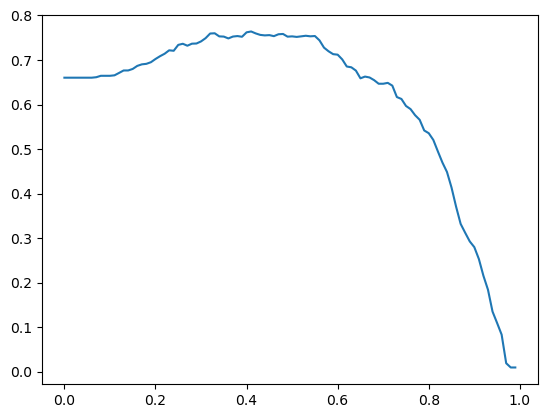

In [59]:
# Encontrando el valor que mejora la capacidad predictiva

umbrales = np.arange(0, 100, 1) / 100
f1s = []
for i in umbrales:
    y_hat_pred_nn = np.where(y_pred_nn > i, 1, 0)
    f1s.append(f1_score(y_hat_pred_nn, y_test))

plt.plot(umbrales, f1s)

Codigo previo:

Este código tiene como objetivo evaluar cómo afecta el umbral de decisión en el rendimiento del modelo medido por el F1-score. El umbral predeterminado para una red neuronal con salida sigmoide es 0.5, pero en este caso, se está probando una serie de umbrales (de 0.00 a 0.99) para observar cuál umbral maximiza el F1-score y, por lo tanto, mejora la clasificación del modelo.

In [60]:
# Este código está buscando el umbral que maximiza el F1-score y lo devuelve
# np.argmax(f1s) devuelve el índice del valor máximo en la lista f1s.
# usa el índice que devuelve np.argmax(f1s) para acceder al valor correspondiente de umbral en el array umbrales.

# Por lo cual se determina el valor del umbral que produjo el F1-score mas alto. 

umbrales[np.argmax(f1s)]

0.41

In [61]:
y_hat_pred_nn = np.where(y_pred_nn > umbrales[np.argmax(f1s)], 1, 0)

confusion_matrix(y_hat_pred_nn, y_test)

array([[145,  37],
       [ 68, 170]], dtype=int64)

- Verdaderos Negativos (TN) -> 145 ( Predicciones correctas de la clase 0 )
- Verdaderos Positivos (TP) -> 170 ( Predicciones correctas de la clase 1 )
- Falsos Positivos (FP) -> 37 ( Predicciones incorrectas donde el modelo predijo 1 pero la etiqueta real era 0 )
- Falsos Negativos (FN) -> 68 ( Predicciones incorrectas donde el modelo predijo 0 pero la etiqueta real era 1 )

Predicciones correctas e incorrectas:
- Predicciones correctas:  315 <- 145 + 170 ( Verdaderos Negativos + Verdaderos Positivos)
- Predicciones incorrectas:  105 <- 37 + 68 (Falsos Positivos + Falsos Negativos)


In [62]:
print(f1_score(y_hat_pred_nn, y_test))
print(accuracy_score(y_hat_pred_nn, y_test))

0.7640449438202247
0.75


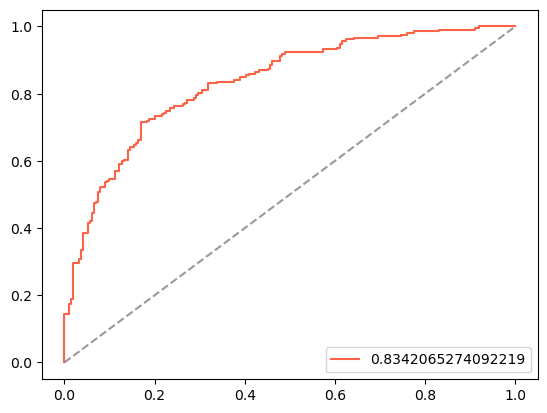

In [63]:
from sklearn.metrics import auc, roc_curve

# Definición de variables para la curva ROC

fpr, tpr, thresholds = roc_curve(y_test, y_pred_nn)
# Gráfico de la curva ROC
plt.plot(fpr, tpr, ls='-', color='tomato', label = auc(fpr, tpr)) # trazado de la curva ROC
plt.plot([0,1], [0,1], ls='--', color='gray', alpha=0.8) # linea diagonal de referencia
plt.legend(loc='lower right'); # indica el valor del AUC de la curva ROC.